# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [2]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [3]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:** Escribe aquí.
1. Cada fila representa un cliente y su información
2. Cada columna representa una variable
3. Es el cliente
4. No, no todas las columnas son características. La columna `cliente_id` es un identificador, y `compra_proximo_mes` es la variable objetivo

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [4]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras:
- Número de columnas:
- ¿Tenemos el mismo número de características? ¿Por qué?

Escribe aquí.
- 400
- 12
- No, tenemos 10 características de 12 columnas, por que `cliente_id` es un identificador y `compra_proximo_mes` es la variable objetivo

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [5]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | str | Categórica nominal | Sí |
| zona | str | Categórica nominal | Sí |
| nivel_fidelidad | str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | str | Target | No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [6]:
# TODO: analiza cliente_id
df["cliente_id"].head(10)

0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64

### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.

Escribe aquí.
1. Un dato entero (`int64`)
2. No
3. No
4. No
5. Un ID único no aporta información relevante ya que solo sirve para identificar cada uno de los registros.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [7]:
# TODO: value_counts() + sort_index()
df["satisfaccion"].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.

Escribe aquí.
1. Como un entero
2. No, es una escala codificada que representa niveles de opinión
3. Sí, un cliente con 5 está más satisfecho que otros con números inferiores y así sucesivamente
4. Categórica ordinal
5. `dtype` solo indica cómo el sistema guarda el dato, mientras que el significado conceptual define su naturaleza

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [8]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 45.1 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

Escribe aquí.
1. 400
2. `float64`, `int64` y `str`
3. No, algunas tienen registros nulos.
4. `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`.
5. `antiguedad_meses`,`ingresos_anuales` y `gasto_mensual`

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [9]:
# TODO: valores ausentes por columna
df.isna().sum()

# TODO: porcentaje de ausentes por columna
(df.isna().mean() * 100).round(2)

cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64

### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

Escribe aquí.
- No, 5 valores ausentes entre 50 muestras representan un porcentaje mucho más alto que si fueran entre 100.000. 
- Los porcentajes normalizan el tamaño de los datos faltantes, permitiendo ver la gravedad

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [ ]:
# TODO: crea y
y = df["compra_proximo_mes"]

# TODO: muestra y.head() y y.shape
print(y.head())
print(y.shape)

### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?

Escribe aquí.
1. Cada elemento representa un dato de un cliente
2. 400
3. El modelo tendría acceso directo a la respuesta que debe predecir, teniendo un resultado perfecto en el primer entrenamiento sin aprender nada

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
# TODO: crea X
features = [
    "edad",
    "antiguedad_meses",
    "ingresos_anuales",
    "gasto_mensual",
    "num_compras",
    "devoluciones",
    "dispositivo",
    "zona",
    "nivel_fidelidad",
    "satisfaccion"
]
X = df[features]

# TODO: muestra X.head() y X.shape
print(X.head())
print(X.shape)

   edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0    67             102.0           9000.00          60.73            7   
1    28              93.0          35683.86         131.74            6   
2    19              87.0          37152.19          55.33            8   
3    55              79.0          40158.29          24.33            7   
4    39               3.0          27317.06          88.78            5   

   devoluciones dispositivo   zona nivel_fidelidad  satisfaccion  
0             3       Móvil  Oeste             Oro             5  
1             1       Móvil   Este          Bronce             2  
2             1   Ordenador   Este           Plata             5  
3             0   Ordenador  Norte          Bronce             4  
4             0       Móvil    Sur          Bronce             4  
(400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n =\) 400 (número de muestras)
- \(p =\) 10 (número de variables para entrenar el modelo)
- \(X.shape =\) `(400, 10)` (matriz bidimensional con 400 filas/muestras y 10 columnas/características)
- \(y.shape =\) `(400,)` (vector unidimensional con las 400 etiquetas objetivo de cada muestra)

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:** Escribe aquí.
1. Sí, `(400, 10)`
2. Sí, `compra_proximo_mes`
3. Sí, cada muestra cuenta con su valor
4. Sí
5. clasificación, porque la variable objetivo tiene valores categóricos discretos
6. Binario, existen dos resultados
7. Las dos clases son `"Sí"` y `"No"`.

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [15]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
for col in ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True) * 100).round(2))

--- dispositivo ---
dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64
--- zona ---
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64
--- nivel_fidelidad ---
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64
--- compra_proximo_mes ---
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50% |
| zona | Este | 89 | 22.25% |
| nivel_fidelidad | Bronce | 162 | 40.50% |
| compra_proximo_mes | No | 246 | 61.50% |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

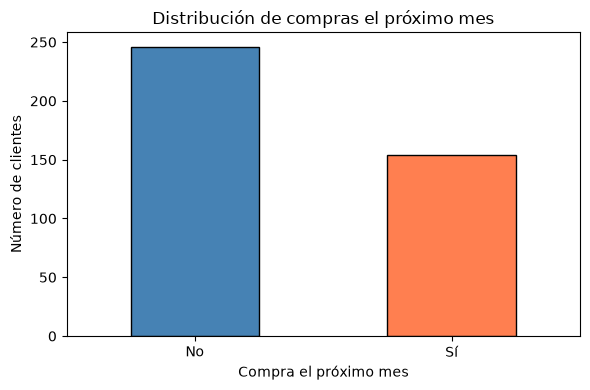

In [16]:
# TODO: gráfico de barras
conteo_target = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(6, 4))
conteo_target.plot(kind="bar", color=["steelblue", "coral"], edgecolor="black")
plt.title("Distribución de compras el próximo mes")
plt.xlabel("Compra el próximo mes")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No, la clase (`No`) tiene 246 clientes, el 61,50% del total, mientras que (`Sí`) 154 clientes, el 38,50%

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [17]:
# TODO: describe() solo sobre las columnas indicadas
cols_num = ["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]
df[cols_num].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** media de 46,40 años (mediana de 45 años), con el 50% central entre 33 y 59 años y un máximo atípico de 195 años que eleva la desviación estándar (18,01)
- **ingresos_anuales:** media de 36.440,92 € (mediana de 36.817,28 €), distribución entre 9.000,00 € y 82.925,37 €, con 4 valores ausentes
- **gasto_mensual:** media de 69,09 € frente a una mediana de 61,17 €, mostrando asimetría positiva hasta un máximo de 260,00 €, con 3 valores ausentes
- **num_compras:** media de 8,23 compras al año (mediana de 8), concentrando la mayoría entre 6 y 10 pedidos, en un rango de 2 a 17
- **devoluciones:** media de 1,23 devoluciones al año (mediana de 1), con el 75% de clientes haciendo 2 o menos y un máximo de 5

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:** Escribe aquí.
1. Sí, `195`
2. En `edad`
3. Es imposible que un cliente tenga 195 años
4. No
5. El resto de variables de esas filas (su antigüedad, gasto o compras) para ver si es válido y solo es un error al introducir la edad, y vería si conviene corregir el dato, ponerlo como ausente (`NaN`) o descartar la fila

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

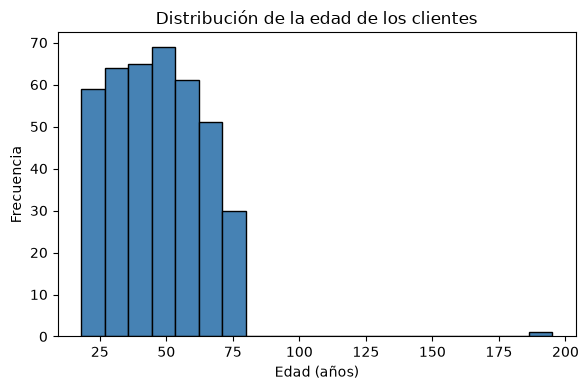

In [18]:
# TODO: histograma de edad
plt.figure(figsize=(6, 4))
plt.hist(df["edad"], bins=20, color="steelblue", edgecolor="black")
plt.title("Distribución de la edad de los clientes")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

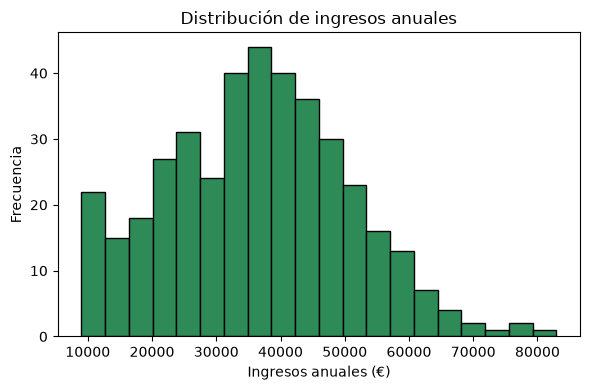

In [19]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(6, 4))
plt.hist(df["ingresos_anuales"].dropna(), bins=20, color="seagreen", edgecolor="black")
plt.title("Distribución de ingresos anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

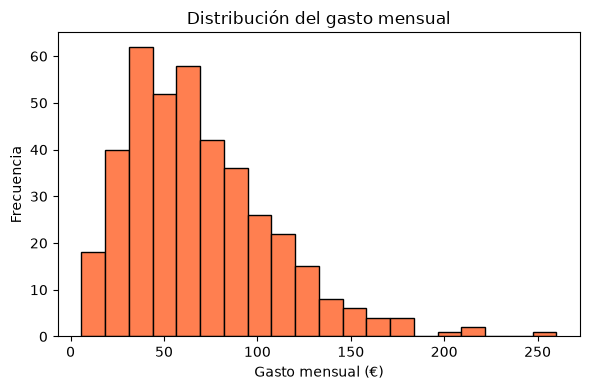

In [20]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(6, 4))
plt.hist(df["gasto_mensual"].dropna(), bins=20, color="coral", edgecolor="black")
plt.title("Distribución del gasto mensual")
plt.xlabel("Gasto mensual (€)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

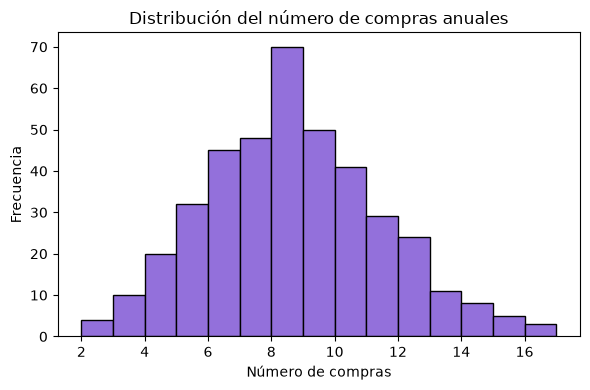

In [21]:
# TODO: histograma de num_compras
plt.figure(figsize=(6, 4))
plt.hist(df["num_compras"], bins=15, color="mediumpurple", edgecolor="black")
plt.title("Distribución del número de compras anuales")
plt.xlabel("Número de compras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Observaciones
- **edad:** concentración entre los 18 y 75 años (pico alrededor de 45-50) y en 195 el valor atípico
- **ingresos_anuales:** campana entre 35.000 y 45.000 €, con una cola hacia los 80.000 €
- **gasto_mensual:** mayoría de clientes entre 30 y 70 € y una cola de casos aislados hasta 260 €
- **num_compras:** campana centrada en 8 compras anuales

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: `compra_proximo_mes` (es la variable que tiene el resultado que queremos predecir).
- ¿Existe \(y\)?: Sí está en el dataset con valores como `"Sí"` y `"No"`.
- Supervisado / no supervisado: Aprendizaje supervisado, porque entrenamos el modelo utilizando ejemplos etiquetados resultado real
- Clasificación / regresión / clustering: Clasificación, ya que la variable objetivo representa categorías discretas
- Binaria / multiclase: Clasificación binaria, porque solo existen dos clases posibles excluyentes (`"Sí"` o `"No"`).

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:** Escribe aquí.
1. `gasto_proximo_mes`
2. Numérica continua
3. Sí, sigue siendo aprendizaje supervisado porque tenemos el valor real
4. Regresión
5. Porque el objetivo es saber una cifra en lugar de etiquetar

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:** Escribe aquí.
1. No
2. No, solo \(X\)
3. Aprendizaje no supervisado, ya que el algoritmo debe descubrir patrones sin respuestas
4. Clustering
5. Variables de comportamiento y perfil como `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `antiguedad_meses`, `nivel_fidelidad` o `satisfaccion`.

### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Escribe aquí.
- Porque el rol de una variable no es una propiedad fija de la columna

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** Escribe aquí.
- No estoy de acuerdo, ya que por un lado `X` sigue incluyendo `cliente_id`, que es un identificador y por otro, contiene datos sin limpiar ni preparar, como valores ausentes en `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`, el valor atípico de `195` en `edad` y variables de texto (`dispositivo`, `zona`, `nivel_fidelidad`) que requieren codificarse antes de nada

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: Cliente individual de la plataforma
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: Categórica binaria (Sí / No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones
Features categóricas nominales: dispositivo, zona
Features ordinales: nivel_fidelidad, satisfaccion
Datos etiquetados: Sí
Valores ausentes: Sí (12 en total: 5 en antiguedad_meses, 4 en ingresos_anuales, 3 en gasto_mensual)
Problema principal: Predecir si un cliente realizará una compra el próximo mes
Tipo de aprendizaje: Supervisado
Tipo de tarea: Clasificación binaria

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
Escribe aquí.
El dataset `clientes_ecommerce.csv` recoge 400 muestras (clientes) y 12 columnas, aunque solo 10 son features válidas para construir la matriz \(X\) `(400, 10)`, ya que descartamos `cliente_id` por ser un simple identificador y separamos `compra_proximo_mes` como nuestro vector objetivo \(y\) `(400,)`. Al disponer de etiquetas conocidas (`Sí` un 38,5% y `No` un 61,5%), estamos ante un conjunto etiquetado apto para aprendizaje supervisado de clasificación binaria, presentando un ligero desbalanceo entre clases. A nivel conceptual combina variables numéricas discretas (`edad`, `antiguedad_meses`, `num_compras`, `devoluciones`), numéricas continuas (`ingresos_anuales`, `gasto_mensual`), categóricas nominales (`dispositivo`, `zona`) y ordinales (`nivel_fidelidad` y `satisfaccion`, pese a almacenarse esta última como entero). Respecto a la calidad del dato, detectamos 12 valores ausentes repartidos entre antigüedad, ingresos y gasto mensual, junto a un valor atípico erróneo de 195 años en `edad`. Por su parte, las distribuciones reflejan un claro predominio del móvil (60,5%) y una marcada asimetría positiva en el gasto mensual. En definitiva, tras imputar los nulos, limpiar el outlier y codificar las variables categóricas, el dataset queda listo para entrenar modelos predictivos.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [23]:
# TODO: ampliación opcional
print("1. Gasto mensual medio por nivel de fidelidad:")
print(df.groupby("nivel_fidelidad")["gasto_mensual"].mean().round(2))

print("2. Gasto mensual medio según compra el próximo mes:")
print(df.groupby("compra_proximo_mes")["gasto_mensual"].mean().round(2))

print("3. Número medio de compras por dispositivo:")
print(df.groupby("dispositivo")["num_compras"].mean().round(2))

print("4. Satisfacción media por nivel de fidelidad:")
print(df.groupby("nivel_fidelidad")["satisfaccion"].mean().round(2))

print("5. Porcentaje de compra el próximo mes por nivel de fidelidad:")
print((pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"], normalize="index") * 100).round(2))

1. Gasto mensual medio por nivel de fidelidad:
nivel_fidelidad
Bronce     68.20
Oro        70.93
Plata      68.69
Platino    69.70
Name: gasto_mensual, dtype: float64
2. Gasto mensual medio según compra el próximo mes:
compra_proximo_mes
No    64.59
Sí    76.34
Name: gasto_mensual, dtype: float64
3. Número medio de compras por dispositivo:
dispositivo
Móvil        8.21
Ordenador    8.24
Tablet       8.24
Name: num_compras, dtype: float64
4. Satisfacción media por nivel de fidelidad:
nivel_fidelidad
Bronce     3.31
Oro        3.37
Plata      3.37
Platino    3.24
Name: satisfaccion, dtype: float64
5. Porcentaje de compra el próximo mes por nivel de fidelidad:
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`